In [6]:
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
%matplotlib inline

In [7]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
len(words)

32033

In [8]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
print(len(words))
print(max(len(w) for w in words))
print(words[:8])

32033
15
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [9]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [10]:
# shuffle up the words
import random
random.seed(42)
random.shuffle(words)

In [11]:
# build the dataset
block_size = 8 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])


> 数据流（`batch_size = 32`，`block_size = 3`，`n_embd = 10`，`n_hidden = 200`，`vocab_size = 27`）：

| 步骤 | 对应层 | 输出 shape |
|---|---|---|
| 输入 batch | — | `Xb (32, 3)` int64 |
| 字符 → 向量 | `Embedding(27, 10)` | `(32, 3, 10)` |
| 拉平拼接 | `Flatten()` | `(32, 30)` |
| 隐层线性 | `Linear(30, 200, bias=False)` | `(32, 200)` |
| 批归一化 | `BatchNorm1d(200)` | `(32, 200)` |
| 非线性 | `Tanh()` | `(32, 200)` |
| 输出层 | `Linear(200, 27)` | `(32, 27)` = logits |
| 损失 | `F.cross_entropy` | 标量 |

> `embcat @ W1 + b1` 的 `b1` 和这里的 `bias=False` 是同一个意思 —— BN 会减掉均值，
> 加在 BN 前面的 bias 会被完全抵消，纯属多余参数。

In [33]:
class Linear:
  """全连接层 y = xW + b
  对应 05.ipynb 的 embcat @ W1 + b1（隐层）和 h @ W2 + b2（输出层）"""

  def __init__(self, fan_in, fan_out, bias=True):
    # fan_in  : 每个样本进来时的特征维
    # fan_out : 每个样本出去时的特征维（= 神经元个数）
    # weight  shape (fan_in, fan_out)
    # 除以 sqrt(fan_in) 是 Kaiming 初始化的简化版：
    #   让 sum(fan_in) 项相加后的方差 ≈ 1，防止激活值随层数指数爆炸/消失
    self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
    # bias shape (fan_out,)，用 0 初始化（比 randn 更可控）
    self.bias = torch.zeros(fan_out) if bias else None

  def __call__(self, x):
    # x          shape (N, fan_in)   N = batch_size
    # self.weight shape (fan_in, fan_out)
    self.out = x @ self.weight          # (N, fan_in) @ (fan_in, fan_out) -> (N, fan_out)
    if self.bias is not None:
      self.out = self.out + self.bias   # (N, fan_out) + (fan_out,) 广播 -> (N, fan_out)
    return self.out

  def parameters(self):
    # bias=False 时只返回 weight 一个张量
    return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
  """批归一化（1d = 特征维是 1 维，即 (N, dim) 输入）
  对应 05.ipynb 的 bnmean / bnvar / bnvar_inv / bnraw / hpreact 那五行，
  外加 05.ipynb 最后要用整个训练集重新 calibrate 的那一步（cell 27）"""

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    # dim: 特征维，即要归一化多少列
    self.eps = eps            # 防止方差为 0 时除零
    self.momentum = momentum  # EMA（指数滑动平均）的更新速率
    self.training = True      # 开关：训练用 batch 统计量，推理用 running 统计量
    # ---- 用反向传播学出来的参数 ----
    self.gamma = torch.ones(dim)   # shape (dim,) 缩放，初始 1
    self.beta = torch.zeros(dim)   # shape (dim,) 平移，初始 0
    # ---- 不参与反向传播的 buffer（用 EMA 更新）----
    self.running_mean = torch.zeros(dim)  # shape (dim,)
    self.running_var = torch.ones(dim)    # shape (dim,)

  def __call__(self, x):
    # x shape (N, dim)
    if self.training:
      if x.ndim == 2:
          dim = 0
      elif x.ndim == 3: # update here: 只对Channel那一维求平均
          dim = (0, 1) # 同时压缩0维和1维
      xmean = x.mean(dim, keepdim=True)  # 沿 batch 维求均值 -> (1, dim)
      xvar = x.var(dim, keepdim=True)    # 沿 batch 维求方差 -> (1, dim)
      # 注意：这里用 unbiased=True（默认），和 05.ipynb 手写版一致
    else:
      xmean = self.running_mean        # (dim,)
      xvar = self.running_var          # (dim,)
    # 归一化成均值 0 方差 1
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps)  # (N,dim)-(1,dim) -> (N,dim)，再逐元素除
    # 再缩放平移，恢复表达能力（否则 tanh 永远只吃 [-1,1] 附近的窄分布）
    self.out = self.gamma * xhat + self.beta          # (dim,)*(N,dim)+(dim,) -> (N,dim)
    # 更新 buffer：running = (1-m)*running + m*batch
    # 这样训练结束后不用像 05.ipynb 那样再跑一遍全量数据去 calibrate
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    # 只有 gamma/beta 是可学习的；running_* 是 buffer
    return [self.gamma, self.beta]


class Tanh:
  """逐元素非线性，shape 不变
  回顾 05.ipynb 的反向：dhpreact = (1 - h**2) * dh"""
  def __call__(self, x):
    self.out = torch.tanh(x)  # 输出范围 (-1, 1)，所以需要 BN 先把输入拉到合理尺度
    return self.out

  def parameters(self):
    return []  # 没有参数


class Embedding:
  """查表：把整数 token 变成向量
  对应 05.ipynb 的 C[Xb]（C shape (vocab_size, n_embd)）"""

  def __init__(self, num_embeddings, embedding_dim):
    # num_embeddings = 词表大小 = 27
    # embedding_dim  = 每个字符的向量维 n_embd = 10
    self.weight = torch.randn((num_embeddings, embedding_dim))  # (27, 10)

  def __call__(self, IX):
    # IX  shape (N, block_size)，dtype int64
    self.out = self.weight[IX]
    # 高级索引：用 (N,3) 的整数张量去取第 0 维 -> (N, 3, 10)
    return self.out

  def parameters(self):
    return [self.weight]


class FlattenConsective:

  def __init__(self, n):
      self.n = n # patch size

  def __call__(self, x):
    # x shape (N, block_size, n_embd)
    B, T, C = x.shape
    # (32, 8, 10) -> (32, 4, 20)
    n = self.n
    x = x.view(B, T//n, C*n)
    if x.shape[1] == 1:
        x = x.squeeze(1)
    self.out = x
    return self.out

  def parameters(self):
    return []


class Sequential:

    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [13]:
# 固定随机种子，保证 Embedding/Linear 的初始化可复现
# 回顾 05.ipynb 用的是 g = torch.Generator().manual_seed(2147483647) 逐个传 generator=，
# 这里用全局 seed，之后所有 torch.randn 都跟着它走
torch.manual_seed(42)


In [34]:
n_embd = 10    # 字符嵌入向量的维度
n_hidden = 200 # 隐层神经元个数

# 顺序即数据流方向：一层接一层，后面用 for 循环串起来
layers = [
  #  32: batchsize
  # (32, 8) int64 -> (32, 8, 10)
  Embedding(vocab_size, n_embd),
  # (32, 8, 10) -> (32, 4, 20)
  FlattenConsective(2),
  # (32, 4, 20) -> (32, 4, 200)
  # bias=False：后面紧跟 BatchNorm，BN 会把整列减掉均值，
  #             所以这里的 bias 无论学到什么都会被抵消掉
  Linear(2 * n_embd, n_hidden, bias=False),
  # (32, 4, 200) -> (32, 4, 200)，归一化到均值 0 方差 1
  BatchNorm1d(n_hidden),
  # (32, 4, 200) -> (32, 4, 200)，非线性
  Tanh(),

  # 重复
  FlattenConsective(2), Linear(2 * n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsective(2), Linear(2 * n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    
  # (32, 200) -> (32, 27) = logits
  Linear(n_hidden, vocab_size),
]

model = Sequential(layers)

with torch.no_grad():
  # 回顾 05.ipynb：W2 = torch.randn(...) * 0.1
  # 让最后一层输出偏小 -> 初始 logits 接近 0 -> softmax 接近均匀分布
  # 初始 loss ≈ -log(1/27) ≈ 3.29（均匀猜测的熵），不会一开始就"盲目自信"
  layers[-1].weight *= 0.1

# 把所有层的参数摊平成一个大 list，训练循环里统一置 grad / 更新
parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # 总参数量
for p in parameters:
  p.requires_grad = True  # 打开自动求导


170897


In [35]:
# check shapes for 4 exmaples
ix = torch.randint(0, Xtr.shape[0], (4,))
Xb, Yb = Xtr[ix], Ytr[ix]
logits = model(Xb)
print(Xb.shape)
for layer in model.layers:
    print(layer.__class__.__name__, ':', tuple(layer.out.shape))

torch.Size([4, 8])
Embedding : (4, 8, 10)
FlattenConsective : (4, 4, 20)
Linear : (4, 4, 200)
BatchNorm1d : (4, 4, 200)
Tanh : (4, 4, 200)
FlattenConsective : (4, 2, 400)
Linear : (4, 2, 200)
BatchNorm1d : (4, 2, 200)
Tanh : (4, 2, 200)
FlattenConsective : (4, 400)
Linear : (4, 200)
BatchNorm1d : (4, 200)
Tanh : (4, 200)
Linear : (4, 27)


In [40]:
# n_embd = 10    
# n_hidden = 68 

n_embd = 24    
n_hidden = 128 

layers = [
  Embedding(vocab_size, n_embd),
  FlattenConsective(2), Linear(2 * n_embd, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsective(2), Linear(2 * n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsective(2), Linear(2 * n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(n_hidden, vocab_size),
]

model = Sequential(layers)

with torch.no_grad():
  layers[-1].weight *= 0.1

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # 总参数量
for p in parameters:
  p.requires_grad = True  # 打开自动求导


76579


In [41]:
# 和 05.ipynb 完全相同的优化循环，区别只有两点：
#   1) 前向变成 for layer in layers（不再逐行写公式）
#   2) 反向直接 loss.backward()（不再手推 softmax / BN 的梯度）
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # ---- 构造 minibatch ----
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))  # (32,) 随机下标
  Xb, Yb = Xtr[ix], Ytr[ix]                           # Xb (32,3) int64, Yb (32,) int64

  # ---- 前向 + 顺手记录每层 shape ----
  # x = Xb                    # (32, 3)
  # for layer in layers:
  #     # 逐层 shape：(32,3) -> (32,3,10) -> (32,30) -> (32,200) -> (32,200) -> (32,200) -> (32,27)
  #     x = layer(x)
  logits = model(Xb)
  loss = F.cross_entropy(logits, Yb)  # logits (32,27) + 标签 (32,) -> 标量
                                 # 相当于 05.ipynb 手写的 dlogits 那三步：
                                 #   softmax(logits) -> 真实类那列 -1 -> 除以 n

  # ---- 反向 ----
  for p in parameters:
    p.grad = None          # 清空上一步的梯度（PyTorch 默认会累加）
  loss.backward()          # 一次链式求导搞定 05.ipynb 里手写的全部公式：
                           #   dlogits / dW2 / db2 / dh / dhpreact / dbngain / dbnbias
                           #   / dhprebn(BN 那个 n*dh - sum(dh) - n/(n-1)*bnraw*sum(dh*bnraw) 的复杂式)
                           #   / dW1 / dembcat / db1 / demb -> 最后 scatter 回 dC

  # ---- 更新：朴素 SGD ----
  lr = 0.1 if i < 150000 else 0.01 # 学习率衰减；05.ipynb 里是 100000
  for p in parameters:
    p.data += -lr * p.grad   # 必须 .data，避免这步被写进计算图

  # ---- 记录 ----
  if i % 10000 == 0: # 每 1 万步打印一次
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    # break # DEBUG
  lossi.append(loss.log10().item())  # 存 log10(loss)，之后画出来是一条直线下降的曲线


      0/ 200000: 3.3038
  10000/ 200000: 2.3921
  20000/ 200000: 2.1996
  30000/ 200000: 2.2621
  40000/ 200000: 2.1388
  50000/ 200000: 1.8988
  60000/ 200000: 1.7694
  70000/ 200000: 1.7330
  80000/ 200000: 1.5903
  90000/ 200000: 1.9108
 100000/ 200000: 1.6868
 110000/ 200000: 1.9568
 120000/ 200000: 2.2694
 130000/ 200000: 2.1256
 140000/ 200000: 1.8785
 150000/ 200000: 1.6727
 160000/ 200000: 1.5090
 170000/ 200000: 1.7793
 180000/ 200000: 1.4552
 190000/ 200000: 1.4612


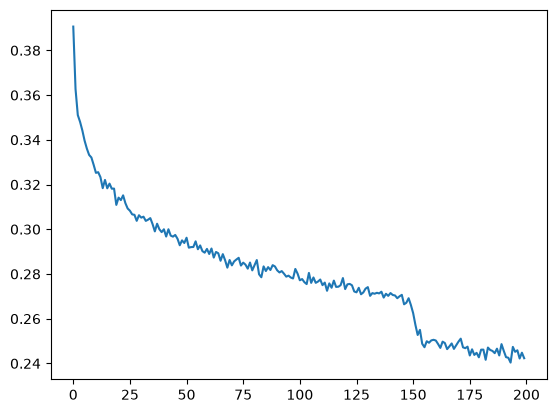

In [37]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))
# 把长长的 loss 序列，按每 1000 个 loss 分成一组
# mean(1)：沿着每组内部求平均

In [38]:
# put layers into eval mode (needed for batchnorm especially)
for layer in model.layers:
  layer.training = False


In [39]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.7343076467514038
val 1.9904423952102661


In [14]:
# sample from the model
# 前提：上面那格 for layer in model.layers: layer.training = False 必须已经跑过，
#       而且之后不能再重跑 model = Sequential([...])，否则 BN 变回训练模式 -> nan
for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass
      x = torch.tensor([context]) # shape (1,3) -> [[0,0,0]]
      logits = model(x)
      # sample
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1).item()
      context = context[1:] + [ix] # 滑动窗口
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))


melae.
lynn.
gwesen.
macoy.
delia.
chrelan.
jaquin.
dayana.
haziyah.
hamilin.
dacy.
grayman.
abella.
kaklyn.
cash.
hamby.
dencelyuh.
card.
malizen.
ronni.


### perf log
context = 3:  
 - train 2.0583250522613525  
 - val 2.1065292358398438

context = 8:
 - train 1.9163438081741333
 - val 2.034247636795044

context = 8 + flattenConsective
 - train 1.7343076467514038
 - val 1.9904423952102661

context = 8 + flattenConsective + scale up n_emb and n_hidden
 - could be better

In [17]:
# 优化计算
model.layers[0].out.shape # output of Embedding layer

torch.Size([1, 8, 10])

In [18]:
model.layers[1].out.shape # output of Flatten layer

torch.Size([1, 80])

In [19]:
model.layers[2].out.shape # output of Linear layer

torch.Size([1, 200])

In [20]:
# a batch of 4 examples
ix = torch.randint(0, Xtr.shape[0], (4,))
Xb, Yb = Xtr[ix], Ytr[ix]
logits = model(Xb)
print(Xb.shape)
Xb

torch.Size([4, 8])


tensor([[ 0,  0,  0,  0,  0,  0, 12,  1],
        [ 0,  0,  0,  0,  0, 11, 15, 12],
        [ 0, 13, 15,  8,  1, 13, 13,  1],
        [13,  1,  4, 13, 21, 19, 20,  1]])

In [21]:
# previous Flatten -> Linear
(torch.randn(4, 80) @ torch.randn(80, 200) + torch.randn(4, 200)).shape

torch.Size([4, 200])

In [23]:
# now 改变 Flaten layer
(torch.randn(4, 4, 20) @ torch.randn(20, 200) + torch.randn(4, 200)).shape

torch.Size([4, 4, 200])

(80, ) @ (80, 200) 权重数量 16,000  
(4,20) @ (20, 200) 权重数量 4,000  
从【每个位置各有一套自己的权重】变成【4个位置共用一套权重】

初始 shape (4, 8)   
4: batch size; 8: context size  
embedding size: 10  
flatten (4, 8, 10) to (4, 80) = 每个input, 摊平之后每个位置对应权重矩阵每一列的不同位置  
优化后  
flatten (4, 8, 10) to (4, 4, 20) = 每个input, 2个字符一组，分成4组，每组对应权重矩阵的位置是一样的  

举例  
优化前某一个input:  
p = [1,2,3,4,1,2,3,4] 对应 w 矩阵 每列的w1,w2...w8， 8个位置输出不同  
合并后  
p = [[1,2,3,4],[1,2,3,4]] = [p1,p2] 两组对应 w 矩阵每列的w1,w2,w3,w4， 若p1=p2，输出相同  

In [26]:
# impl
# e = [
#       [
#        [0,1], [2,3], [4,5], [5,6]
#       ]
#     ]  
# shape (1, 4, 2)
# e[:, ::2, :]   = [[[0,1], [4,5]]]   shape (1, 2, 2)
# e[:, 1::2, :]] = [[[2,3], [5,6]]]   shape (1, 2, 2)
# cat: [[[0,1,2,3], [4,5,6,7]]]       shape (1, 2, 4)
e = torch.randn(4, 8, 10) # goal: (4, 4, 20)
torch.cat([e[:, ::2, :], e[:, 1::2, :]], dim=2).shape

torch.Size([4, 4, 20])